# 03 — Implemented visual system, decisions and narrative
This notebook connects the W3 choices and final presentation to a shared visual implementation. W3 reused the submitted C2 numbers; it did not train new models. Before views are design iterations prepared for W3, not a claim that those exact figures appeared in historical C2 slides.


## 1. Shared rules and working sources
`src/visual_system.json` stores the documented rules. `src/visual_system.py` reads them for these charts. The editable presentation callback reads the same configuration for native slide tables/charts and uses Arial for slide text; notebook figures use DejaVu Sans for portable figure rendering. That font difference is an explicit medium-specific exception.

Static saved views below are the assessed evidence. Editable SVGs and code are retained in `figures/` and `src/`. No interactive runtime is required.


In [1]:
from pathlib import Path
import os,sys,json,hashlib
import numpy as np
import pandas as pd
from IPython.display import display
ROOT=Path.cwd().parent
sys.path.insert(0,str(ROOT))
PRIVATE=Path(os.environ['C3_PRIVATE_INPUT_ROOT'])
pd.set_option('display.max_rows',30)
pd.set_option('display.max_columns',14)
FIG=ROOT/'figures'
from src.visual_system import THEME,composition,metrics,confusion
display(pd.Series(THEME))


font                                                DejaVu Sans
slide_font                                                Arial
ink                                                     #14283D
model                                                   #16446D
attention                                               #A95810
reference                                               #74899E
context                                                 #CCD8E3
grid                                                    #DBE3EB
background                                              #FFFFFF
rules         [Navy identifies model evidence; grey identifi...
dtype: object

## 2. Summarise the class balance
Action + target: summarise long-case composition across chronological partitions. The redesign replaces parallel bars with a 100% stack and preserves all values. Position identifies the partition, length represents share and amber draws attention to long cases.

Limitation: normalisation hides volume and can make small differences difficult to see. A reader could assume equal sample sizes. We keep this form for composition and show row counts; a dot view of long shares would better compare small changes.


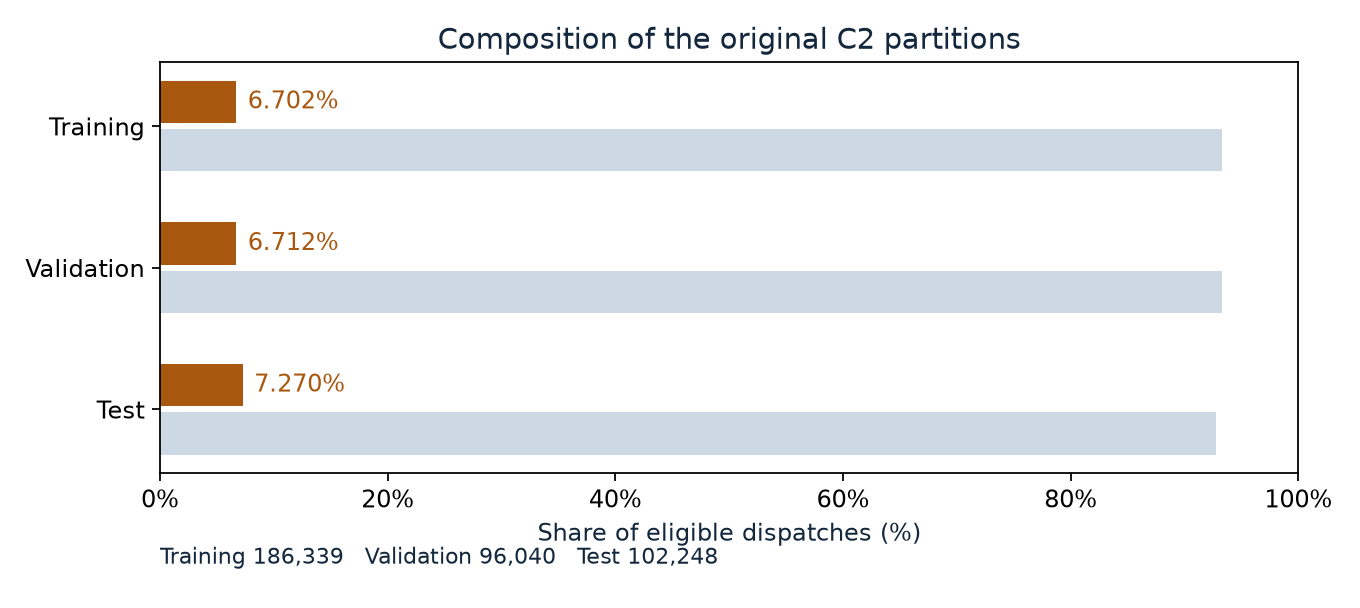

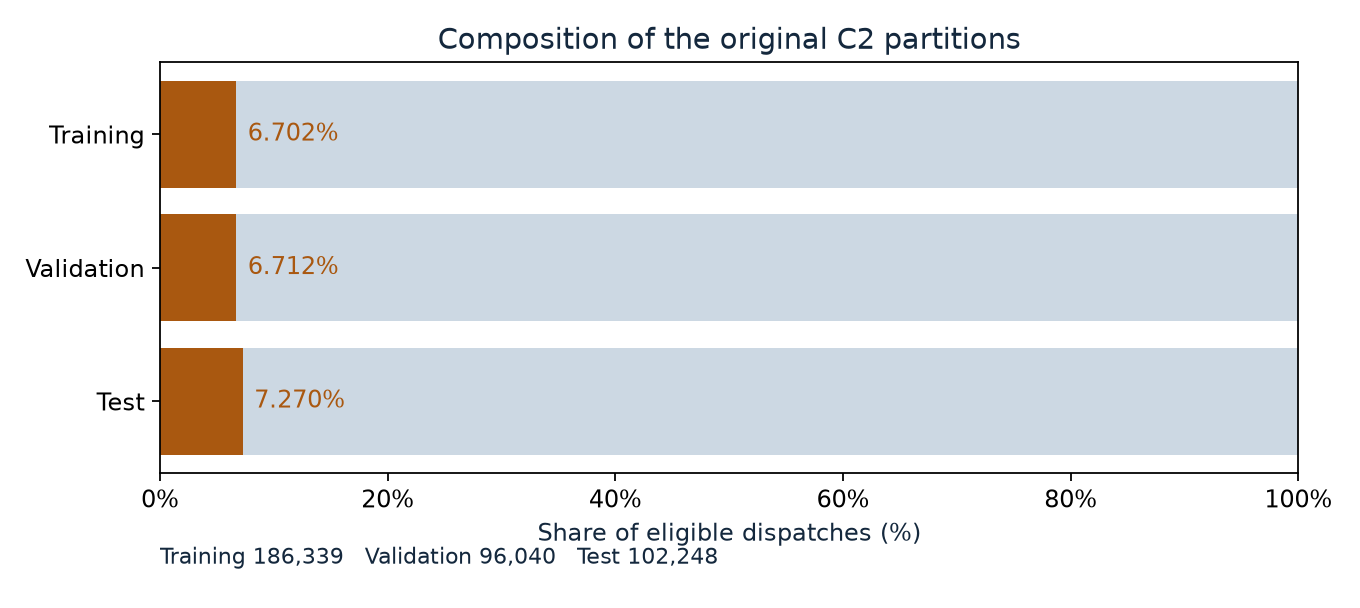

In [2]:
display(composition(False,FIG))
display(composition(True,FIG))


## 3. Compare the model with the reference
Action + target: compare corresponding scores on one 0–100% scale. The redesign uses connected points rather than grouped bars, supporting direct pairwise comparison. Shapes/labels identify model and reference without colour alone.

Limitation: one score cut-off hides the operating trade-off. Readers could assume the chart selected the threshold. We keep it to compare the frozen C2 methods; the final model selection is documented separately in notebook 02. A precision–recall view could explore operating choices in validation.


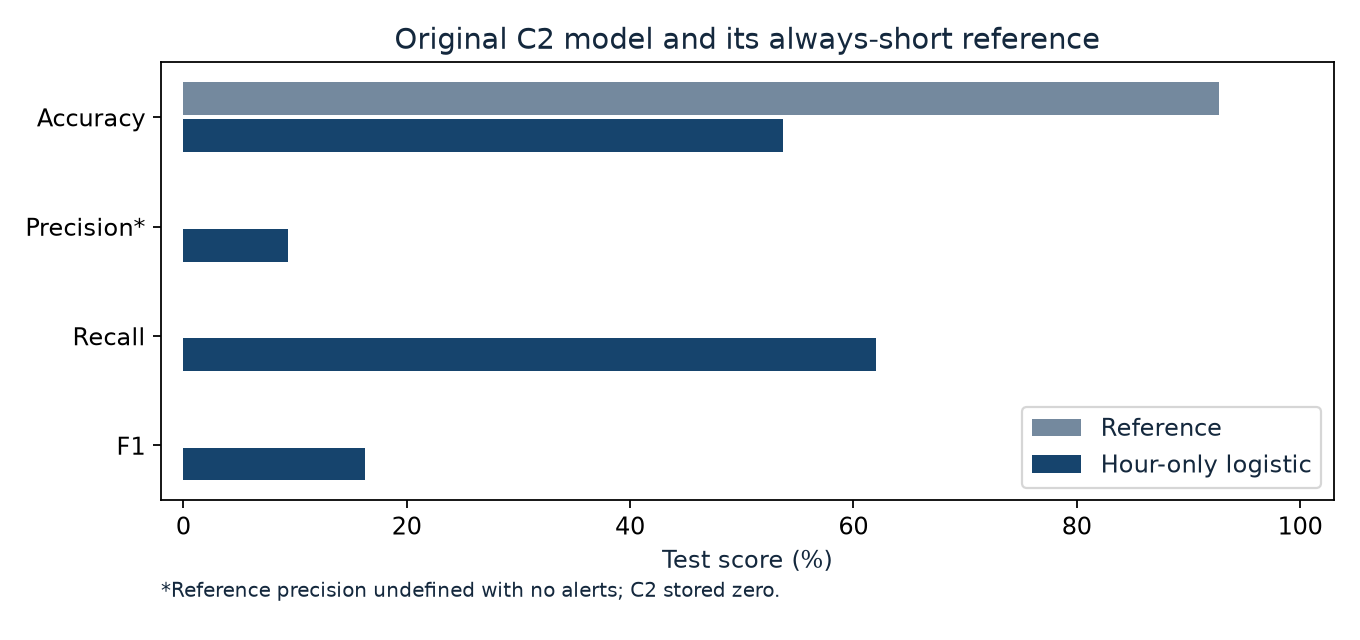

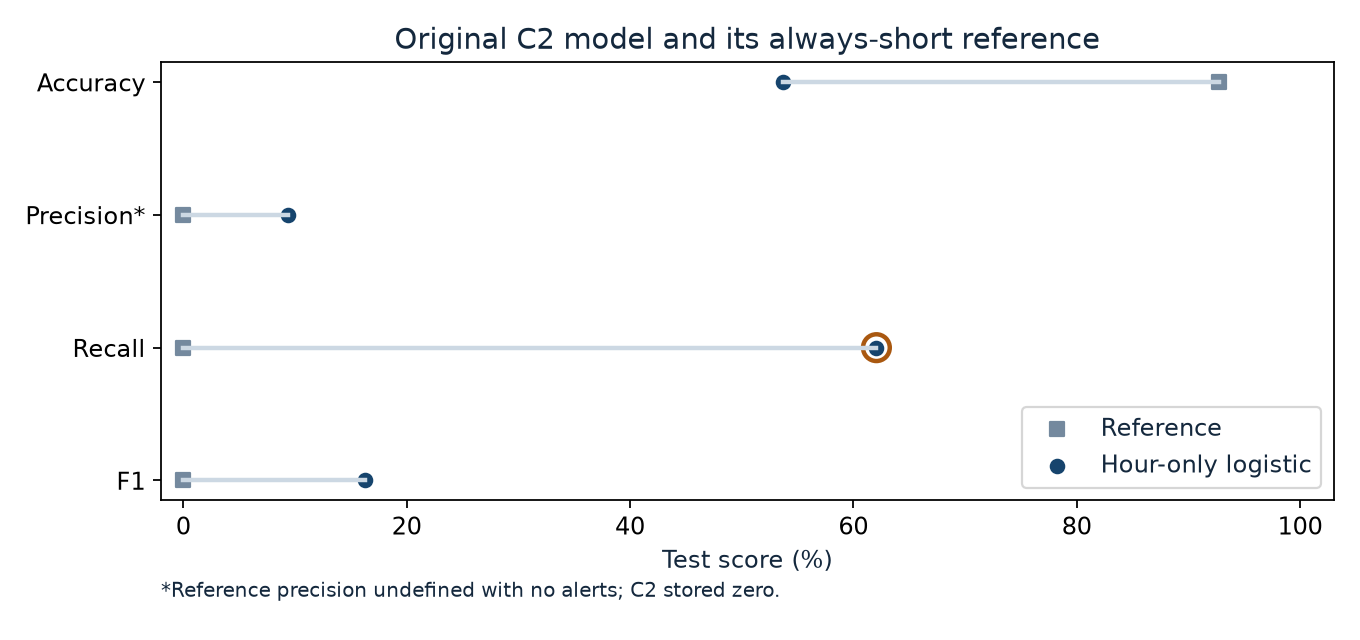

In [3]:
display(metrics(False,FIG))
display(metrics(True,FIG))


## 4. Identify missed long cases
Action + target: identify the C2 error counts relevant to missed long cases. The matrix redesign adds semantic labels and an amber outline around false negatives, retaining the same orientation and counts. This focuses attention on the question rather than automatically highlighting the largest cell.

Limitation: counts have different class denominators. A reader could compare FP and FN as if they were class-specific rates. We keep counts for workload and would add row percentages for within-class comparisons. The final selected model's separate matrix appears in notebook 02.


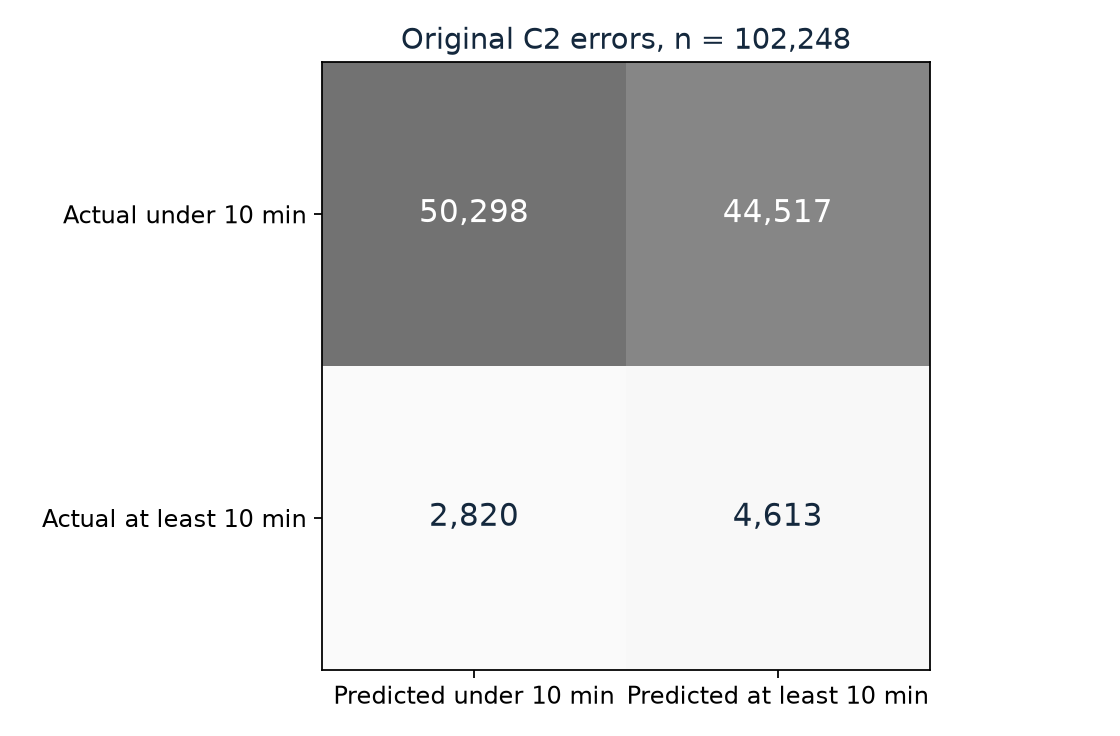

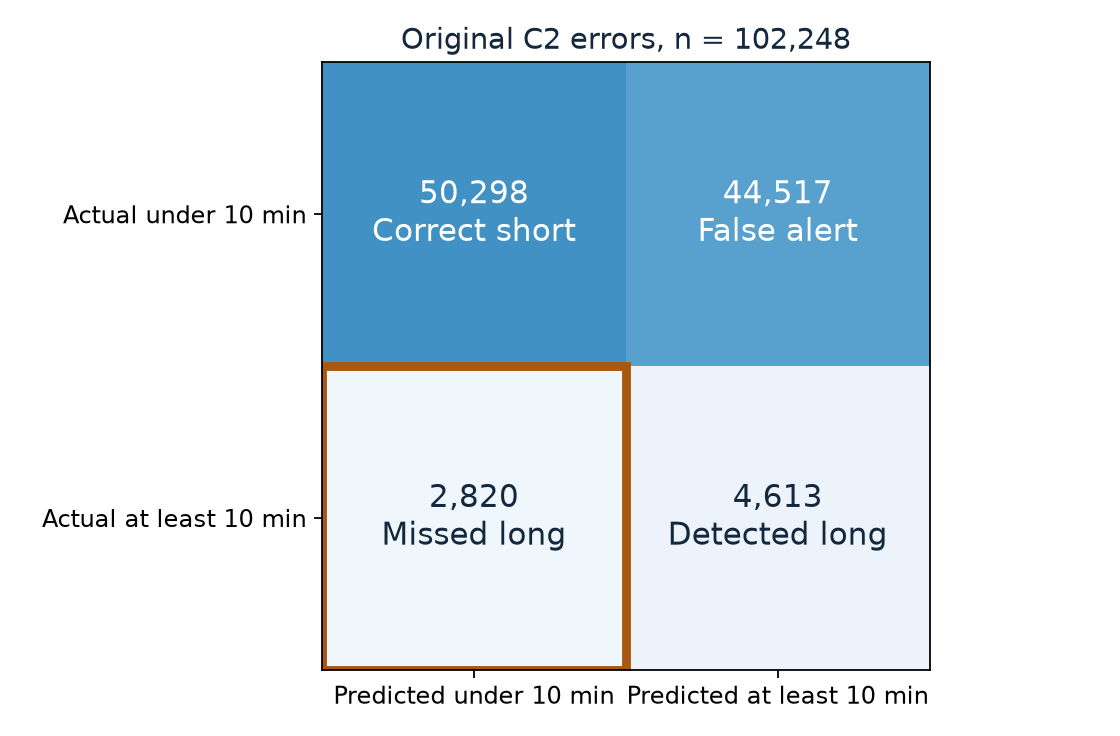

In [4]:
display(confusion(False,FIG))
display(confusion(True,FIG))


## 5. Decisions connected to evidence
W1/C1/W2/C2/W3 are stages of the same question, not independent products. The record below connects the consequence of each choice to saved evidence, including choices retained despite weak results. The final C3 presentation contains two explicitly marked sections: the simulated planning audience and the instructor's internal review.


In [5]:
decisions=[
 ['W1','Prefer arrival-time geography over volume','Duration and borough supported a bounded planning question','Retained and narrowed to 2023–2024','01 §1 and §3'],
 ['C1 feedback / W2','Replace moving percentile comparison with fixed indicator','P90 changes with the data; a fixed 600s outcome preserves definition','Changed KPI; retained P90 descriptively','01 introduction and summaries'],
 ['W2','Keep Unknown and coherent totals','Missing geography/components need not invalidate a timestamp-consistent duration','Retained with flags','01 §2'],
 ['W2','Chronological partitions with no incident overlap','Prediction uses earlier evidence; related vehicles should not cross groups','Retained, with retrospective caveat','02 §2'],
 ['C2','Use hour-only logistic and always-short reference','Simple model exposes poor minority-class performance','Retained as official historical baseline','02 §5'],
 ['C2 feedback','Compare tree/forest and reduce FN','Original C2 missed 2,820 long cases','Compared algorithms and validation operating policies','02 §6'],
 ['W3','Three tasks share visual rules','Composition, paired scores and errors require different encodings','Selected stack, connected points and labelled matrix','03 §2–4'],
 ['Final extension','Join location and compute past-only histories','More context may distinguish delays; availability remains conditional','Kept unmatched rows; excluded current realised outcomes','02 §1 and §3'],
 ['Final selection','Choose logistic with validation recall >=85%','86.71% test recall; 16.11% precision; sensitive option adds 13,420 FP for 400 TP','Retained simple experimental model','02 §4 and §6'],
 ['C3','Two audience-specific arguments, questions within 10min','External audience needs decision and limits; reviewer needs reasons and evidence','Replaced the earlier 9min single talk','Presentation sections 1 and 2']]
display(pd.DataFrame(decisions,columns=['Stage / feedback','Decision','Reason / evidence','Change or retention','Saved evidence']))


,Stage / feedback,Decision,Reason / evidence,Change or retention,Saved evidence
0,W1,Prefer arrival-time geography over volume,Duration and borough supported a bounded plann...,Retained and narrowed to 2023–2024,01 §1 and §3
1,C1 feedback / W2,Replace moving percentile comparison with fixe...,P90 changes with the data; a fixed 600s outcom...,Changed KPI; retained P90 descriptively,01 introduction and summaries
2,W2,Keep Unknown and coherent totals,Missing geography/components need not invalida...,Retained with flags,01 §2
3,W2,Chronological partitions with no incident overlap,Prediction uses earlier evidence; related vehi...,"Retained, with retrospective caveat",02 §2
4,C2,Use hour-only logistic and always-short reference,Simple model exposes poor minority-class perfo...,Retained as official historical baseline,02 §5
5,C2 feedback,Compare tree/forest and reduce FN,"Original C2 missed 2,820 long cases",Compared algorithms and validation operating p...,02 §6
6,W3,Three tasks share visual rules,"Composition, paired scores and errors require ...","Selected stack, connected points and labelled ...",03 §2–4
7,Final extension,Join location and compute past-only histories,More context may distinguish delays; availabil...,Kept unmatched rows; excluded current realised...,02 §1 and §3
8,Final selection,Choose logistic with validation recall >=85%,86.71% test recall; 16.11% precision; sensitiv...,Retained simple experimental model,02 §4 and §6
9,C3,"Two audience-specific arguments, questions wit...",External audience needs decision and limits; r...,Replaced the earlier 9min single talk,Presentation sections 1 and 2


## 6. Narrative choice and individual responsibilities
**Audience presentation:** question, evidence, alternative, bounded recommendation. The simulated planning analyst receives magnitude and uncertainty without the full technical search.

**Internal review:** decision, effect, repository evidence and learning. This explains how a fixed outcome, leakage controls, model comparisons and W3 design shaped the final message. These simple analytical arguments follow classes 13–14; naming multiple frameworks would not add evidence.

The table below records the **agreed final review and defense responsibilities**. Both members share responsibility for the completed study and explain substantive evidence in both presentations. Technical code assistance and automated checks are disclosed separately; the assigned roles do not imply unaided code authorship. Each member must understand the full study beyond the speaking assignment.


In [6]:
display(pd.DataFrame([
 ['Matías Muñoz Hoffmann','Question, unit, fixed KPI, interpretation of patterns and visual/narrative choices','Audience slides 1 and 3; internal review slides 5 and 7','Assigned final review/defense responsibility; unaided code authorship not claimed'],
 ['Clemente Ibarra','Preparation, model/reference comparison, evaluation, limits and feasible next checks','Audience slides 2 and 4; internal review slides 6 and 8','Assigned final review/defense responsibility; unaided code authorship not claimed'],
 ['Both members','Own the final study and explain beyond their speaking section','Both presentations and questions','Shared final review and evidence-based defense responsibility']
 ],columns=['Member','Responsibility','Presentation role','Evidence boundary']))


,Member,Responsibility,Presentation role,Evidence boundary
0,Matías Muñoz Hoffmann,"Question, unit, fixed KPI, interpretation of p...",Audience slides 1 and 3; internal review slide...,Assigned final review/defense responsibility; ...
1,Clemente Ibarra,"Preparation, model/reference comparison, evalu...",Audience slides 2 and 4; internal review slide...,Assigned final review/defense responsibility; ...
2,Both members,Own the final study and explain beyond their s...,Both presentations and questions,Shared final review and evidence-based defense...


### AI use and checks
OpenAI Codex supported source review, code, experiments, plots, documentation and presentation drafting. The recorded technical checks include exact reproduction of original C2 counts, event-time feature checks, fresh model refits and consistency checks against saved outputs. This does not establish personal unaided authorship or individual understanding. No live AI assistance forms part of the defense.

The reviewer can assess this saved record without running it. The oral defense must still demonstrate each student's own understanding.


In [7]:
display(pd.Series(json.loads((PRIVATE/'C2_Precision_Recall_85_90/outputs/fresh_refit_verification.json').read_text())))
print('Editable visual sources:', 'src/visual_system.py and src/visual_system.json')
print('Presentation source:', 'presentations/build_presentations.mjs')


independent_fresh_fits                                                    7
verified_policies                                                         5
checks                    [{'key': 'blend_common_base_85', 'TN': 57528, ...
all_passed                                                             True
dtype: object

Editable visual sources: src/visual_system.py and src/visual_system.json
Presentation source: presentations/build_presentations.mjs
